# Macao visitor arrivals and hotel occupancy
January 2024–December 2025 · 24 monthly observations

Research question: Is there a positive association between monthly visitor arrivals and the average hotel room occupancy rate in Macao?

This period matches both submitted notebooks; it differs from the earlier 2023–2024 proposal. Two original spreadsheet files supplied with the notebooks are included. The occupancy spreadsheet includes a longer series, so the dates are filtered explicitly. No online revision check has been performed.

Source reference: Statistics and Census Service (DSEC), Macao SAR — [Visitor arrivals database](https://www.dsec.gov.mo/timeseriesdatabase.aspx?keyindicatorid=27&lang=en-US) and [monthly indicator definitions](https://www.dsec.gov.mo/WebServices/ListOfKeyIndicatorID.aspx?lang=en-US).

Run from this folder. Required packages: pandas, numpy, scipy, matplotlib, openpyxl and xlrd.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

def read_monthly(path, variable):
    if variable == "Visitors":
        sheets = pd.read_excel(path, sheet_name=None, header=None)
        raw = next(table for table in sheets.values() if table.shape[1] == 3)
        month_names = dict(zip(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], range(1, 13)))
        years = pd.to_numeric(raw.iloc[:, 0], errors="coerce").ffill()
        months = raw.iloc[:, 1].astype(str).str[:3].map(month_names)
        valid = years.notna() & months.notna()
        data = pd.DataFrame({
            "Month": pd.to_datetime(dict(year=years[valid].astype(int), month=months[valid].astype(int), day=1)),
            variable: pd.to_numeric(raw.loc[valid, 2], errors="raise")
        })
        return data.loc[data["Month"].between("2024-01-01", "2025-12-01")]
    raw = pd.read_excel(path, header=None)
    dates = raw.iloc[:, 0].astype(str).str.extract(r"^(\d{4})年(\d{1,2})月$")
    valid = dates.notna().all(axis=1)
    data = pd.DataFrame({
        "Month": pd.to_datetime(dates.loc[valid, 0] + "-" + dates.loc[valid, 1] + "-01"),
        variable: pd.to_numeric(raw.loc[valid, 1].astype(str).str.replace(",", ""), errors="raise")
    })
    return data.loc[data["Month"].between("2024-01-01", "2025-12-01")]

occ = read_monthly("酒店入住率（202401-202512）.xlsx", "OccupancyRate")
vis = read_monthly("入境旅客总数（202401-202512）.xls", "Visitors")
df = occ.merge(vis, on="Month", how="outer", validate="one_to_one").sort_values("Month").reset_index(drop=True)
assert len(df) == 24 and not df.isna().any().any()
assert df["Month"].tolist() == list(pd.date_range("2024-01-01", "2025-12-01", freq="MS"))
assert df["OccupancyRate"].between(0, 100).all() and (df["Visitors"] > 0).all()
df["Year"] = df["Month"].dt.year
df.to_csv("monthly_data_2024_2025.csv", index=False, date_format="%Y-%m")
print(f"Merged {len(df)} complete monthly observations, {df.Month.min():%Y-%m} to {df.Month.max():%Y-%m}.")


Merged 24 complete monthly observations, 2024-01 to 2025-12.


In [2]:
r, p = pearsonr(df["Visitors"], df["OccupancyRate"])
slope, intercept = np.polyfit(df["Visitors"] / 1e6, df["OccupancyRate"], 1)
print(f"Pearson r = {r:.6f}; conventional two-sided p = {p:.3e}; n = {len(df)}")
print(f"Optional fitted line: occupancy (%) = {intercept:.3f} + {slope:.3f} × arrivals (millions)")
print(f"In-sample R² = {r*r:.4f}")
for year, group in df.groupby("Year"):
    print(f"Within {year}: r = {pearsonr(group.Visitors, group.OccupancyRate).statistic:.4f}, n = {len(group)}")
changes = df[["Visitors", "OccupancyRate"]].diff().dropna()
print(f"Month-to-month changes: r = {pearsonr(changes.Visitors, changes.OccupancyRate).statistic:.4f}, n = {len(changes)}")
print(f"Same direction in {(changes.Visitors * changes.OccupancyRate > 0).sum()} of {len(changes)} month-to-month transitions.")


Pearson r = 0.823131; conventional two-sided p = 7.857e-07; n = 24
Optional fitted line: occupancy (%) = 69.271 + 5.959 × arrivals (millions)
In-sample R² = 0.6775
Within 2024: r = 0.7443, n = 12
Within 2025: r = 0.8139, n = 12
Month-to-month changes: r = 0.8377, n = 23
Same direction in 17 of 23 month-to-month transitions.


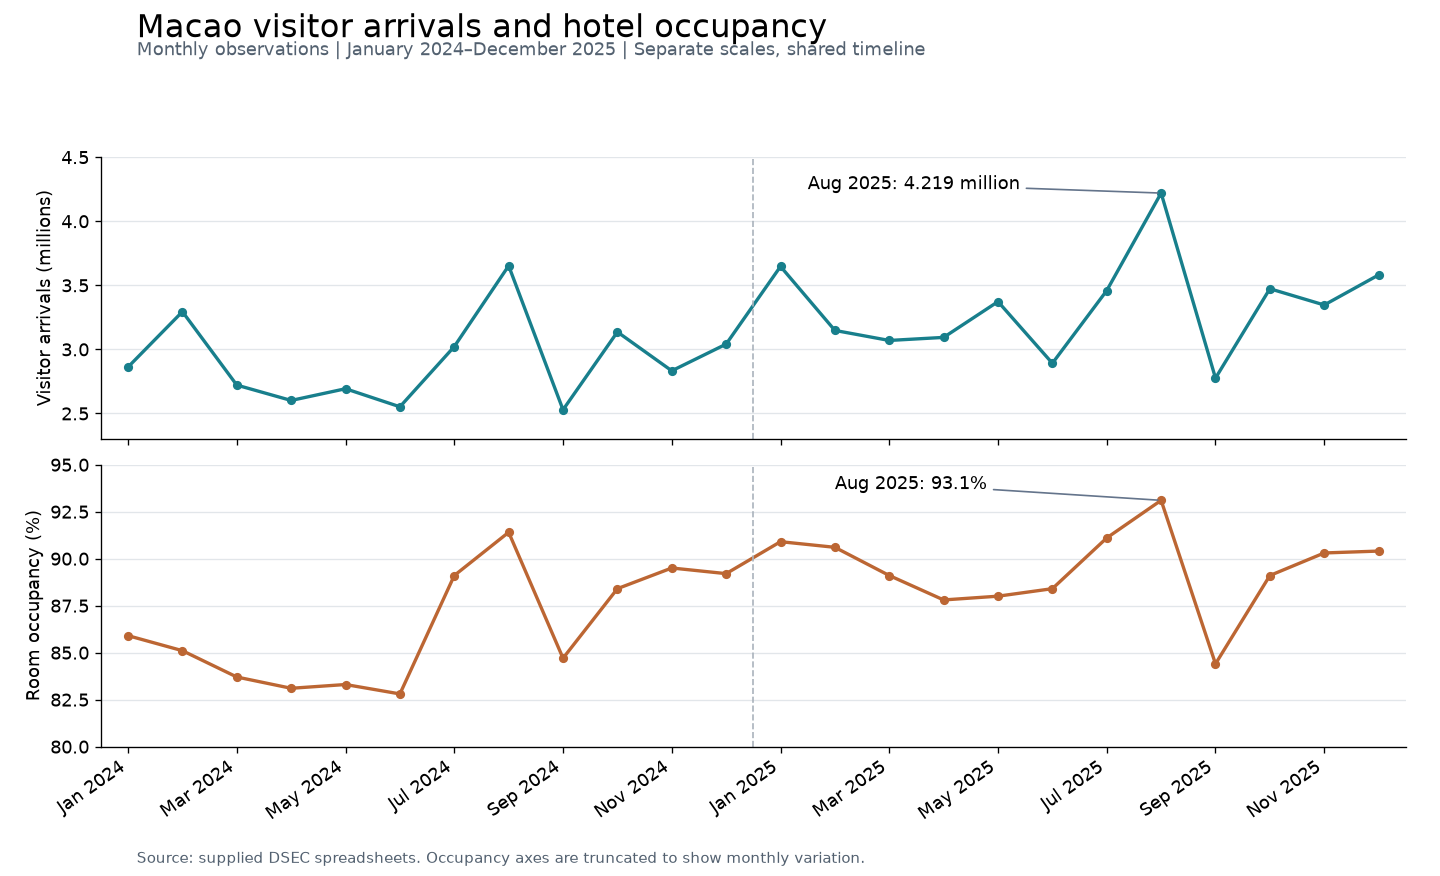

In [3]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "savefig.facecolor": "white"})
fig, axes = plt.subplots(2, 1, figsize=(12, 7.3), sharex=True)
x = np.arange(len(df))
for ax, values, color, label, limits in [
    (axes[0], df.Visitors / 1e6, "#187F8C", "Visitor arrivals (millions)", (2.3, 4.5)),
    (axes[1], df.OccupancyRate, "#BC6633", "Room occupancy (%)", (80, 95))
]:
    ax.plot(x, values, color=color, marker="o", linewidth=2, markersize=4.5)
    ax.set_ylabel(label)
    ax.set_ylim(*limits)
    ax.grid(axis="y", color="#E2E6EA")
    ax.axvline(11.5, color="#AAB3BC", linestyle="--", linewidth=1)
    ax.set_xlim(-0.5, 23.5)
axes[1].set_xticks(x[::2], df.Month.dt.strftime("%b %Y").iloc[::2], rotation=35, ha="right")
axes[0].annotate("Aug 2025: 4.219 million", (19, df.Visitors.iloc[19]/1e6), xytext=(12.5, 4.25), arrowprops={"arrowstyle":"-", "color":"#64748B"})
axes[1].annotate("Aug 2025: 93.1%", (19, df.OccupancyRate.iloc[19]), xytext=(13, 93.7), arrowprops={"arrowstyle":"-", "color":"#64748B"})
fig.suptitle("Macao visitor arrivals and hotel occupancy", fontsize=19, x=.095, ha="left", y=.985)
fig.text(.095, .937, "Monthly observations | January 2024–December 2025 | Separate scales, shared timeline", color="#536170")
fig.text(.095, .015, "Source: supplied DSEC spreadsheets. Occupancy axes are truncated to show monthly variation.", fontsize=9, color="#536170")
fig.tight_layout(rect=(.01,.035,.99,.91))
fig.savefig("monthly_trends.png", dpi=200)
plt.show()


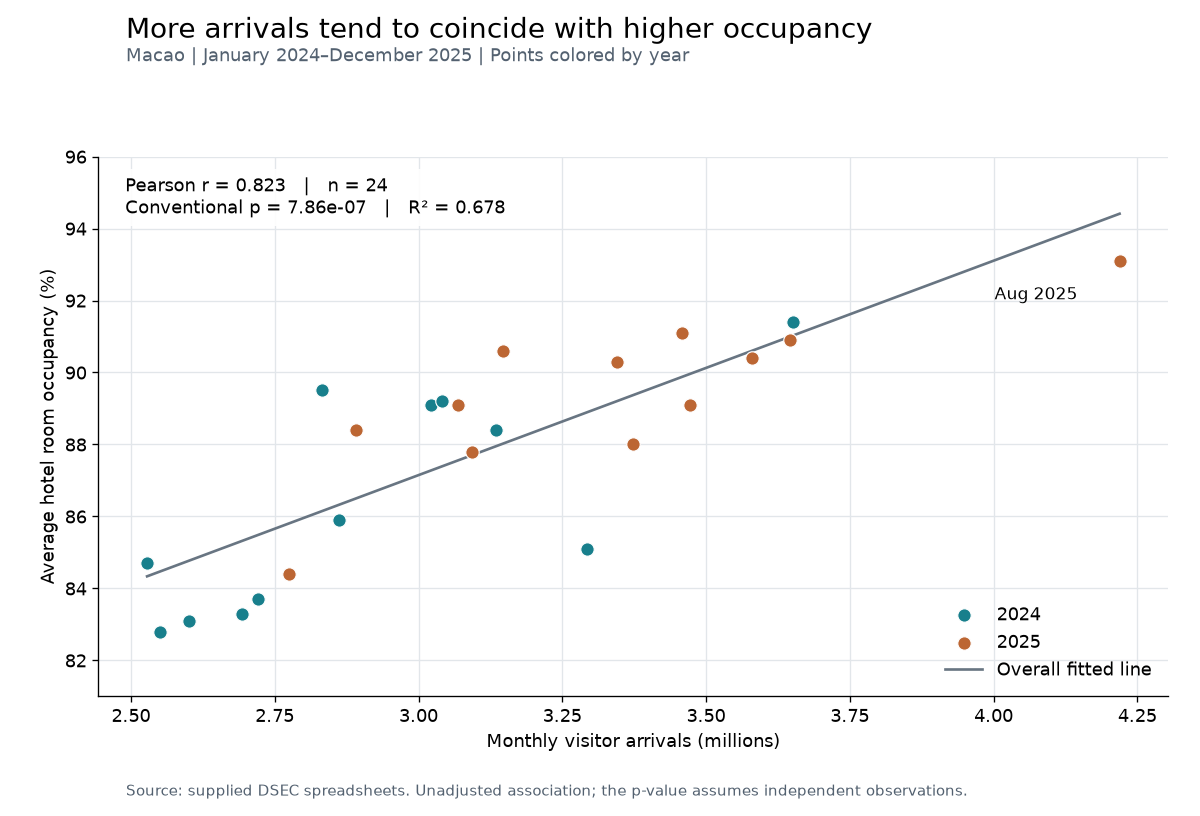

In [4]:
fig, ax = plt.subplots(figsize=(10, 6.8))
for year, color in [(2024, "#187F8C"), (2025, "#BC6633")]:
    group = df.loc[df.Year == year]
    ax.scatter(group.Visitors / 1e6, group.OccupancyRate, s=65, color=color, label=str(year), edgecolor="white", linewidth=.7, zorder=3)
xx = np.linspace(df.Visitors.min()/1e6, df.Visitors.max()/1e6, 100)
ax.plot(xx, intercept + slope*xx, color="#687582", linewidth=1.6, label="Overall fitted line")
ax.annotate("Aug 2025", (df.Visitors.iloc[19]/1e6, df.OccupancyRate.iloc[19]), xytext=(-75, -23), textcoords="offset points", fontsize=10)
ax.set(xlabel="Monthly visitor arrivals (millions)", ylabel="Average hotel room occupancy (%)", ylim=(81,96))
ax.grid(color="#E2E6EA", zorder=0)
ax.legend(loc="lower right", frameon=False)
ax.text(.025, .965, f"Pearson r = {r:.3f}   |   n = 24\nConventional p = {p:.2e}   |   R² = {r*r:.3f}", transform=ax.transAxes, va="top", fontsize=11, bbox={"facecolor":"white", "edgecolor":"none", "alpha":.9})
fig.suptitle("More arrivals tend to coincide with higher occupancy", fontsize=17, x=.105, ha="left", y=.98)
fig.text(.105,.925,"Macao | January 2024–December 2025 | Points colored by year",color="#536170")
fig.text(.105,.025,"Source: supplied DSEC spreadsheets. Unadjusted association; the p-value assumes independent observations.",fontsize=9,color="#536170")
fig.tight_layout(rect=(.015,.055,.99,.90))
fig.savefig("arrivals_vs_occupancy.png", dpi=200)
plt.show()


## Conclusion

Across 24 monthly observations from January 2024 to December 2025, visitor arrivals and the average hotel room occupancy rate in Macao showed a strong positive association (Pearson r = 0.823). The conventional two-sided Pearson test yielded p = 7.86e-07, below 0.001, assuming independent observations. Months with more arrivals generally had higher occupancy, although the two measures did not always move in the same direction. Both reached their highest observed values in August 2025, at 4,219,034 arrivals and 93.1% occupancy. These results describe an association and do not establish that increased arrivals caused higher occupancy. Seasonality, dependence between consecutive months, room supply and the proportion of overnight visitors were not controlled for, so the statistical significance should be interpreted cautiously.

Optional regression: R² = 0.678 describes the fit within these 24 observations. It does not mean that visitors caused 67.8% of occupancy, and it is not an out-of-sample prediction score.

The within-year and month-to-month correlations above are descriptive checks; they do not replace a time-series model or seasonality adjustment.